## Skeleton Code

The code below provides a skeleton for the model building & training component of your project. You can add/remove/build on code however you see fit, this is meant as a starting point.

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import json
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt

##Import any other stats/DL/ML packages you may need here. E.g. Keras, scikit-learn, etc.
from itertools import chain
from skimage.io import imread
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_curve, auc, precision_recall_curve, average_precision_score,
                             f1_score, confusion_matrix, precision_score, recall_score)

from keras.preprocessing.image import ImageDataGenerator
from keras.applications.vgg16 import VGG16
from keras.models import Model, Sequential
from keras.layers import Dense, Dropout, Flatten
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
IMG_SIZE = (224, 224)   # VGG16 input size

Using TensorFlow backend.


## Do some early processing of your metadata for easier model training:

In [2]:
## Below is some helper code to read all of your full image filepaths into a dataframe for easier manipulation
## Load the NIH data to all_xray_df
all_xray_df = pd.read_csv('/data/Data_Entry_2017.csv')
all_image_paths = {os.path.basename(x): x for x in 
                   glob(os.path.join('/data','images*', '*', '*.png'))}
print('Scans found:', len(all_image_paths), ', Total Headers', all_xray_df.shape[0])
all_xray_df['path'] = all_xray_df['Image Index'].map(all_image_paths.get)
all_xray_df.sample(3)

Scans found: 112120 , Total Headers 112120


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,path
89645,00022260_003.png,No Finding,3,22260,54,F,PA,2542,2434,0.143,0.143,NaN,/data/images_010/images/00022260_003.png
47446,00012048_007.png,Infiltration|Mass|Nodule,7,12048,65,M,AP,2500,2048,0.168,0.168,NaN,/data/images_006/images/00012048_007.png
57963,00014352_005.png,No Finding,5,14352,6,M,PA,2992,2033,0.143,0.143,NaN,/data/images_007/images/00014352_005.png


In [3]:
## Here you may want to create some extra columns in your table with binary indicators of certain diseases
## rather than working directly with the 'Finding Labels' column

all_labels = np.unique(list(chain(*all_xray_df['Finding Labels'].map(lambda x: x.split('|')).tolist())))
all_labels = [x for x in all_labels if len(x) > 0]
print('All Labels ({}): {}'.format(len(all_labels), all_labels))

for c_label in all_labels:
    all_xray_df[c_label] = all_xray_df['Finding Labels'].map(lambda finding: 1.0 if c_label in finding.split('|') else 0.0)

# drop records with implausible ages (data-entry errors found in EDA) and missing images
all_xray_df = all_xray_df[(all_xray_df['Patient Age'] <= 100) & (all_xray_df['path'].notnull())].reset_index(drop=True)
all_xray_df.sample(3)

All Labels (15): ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,...,Emphysema,Fibrosis,Hernia,Infiltration,Mass,No Finding,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
105837,00028504_001.png,No Finding,1,28504,61,F,PA,2021,2021,0.194311,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
24847,00006521_001.png,No Finding,1,6521,55,F,PA,2048,2500,0.171000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
101993,00027142_007.png,Atelectasis,7,27142,56,F,AP,3056,2544,0.139000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
## Here we can create a new column called 'pneumonia_class' that will allow us to look at
## images with or without pneumonia for binary classification

all_xray_df['pneumonia_class'] = all_xray_df['Pneumonia'].astype(int)
# flow_from_dataframe with class_mode='binary' wants string labels
all_xray_df['pneumonia_str'] = all_xray_df['pneumonia_class'].astype(str)

print(all_xray_df['pneumonia_class'].value_counts())

0    110674
1      1430
Name: pneumonia_class, dtype: int64


## Create your training and testing data:

In [5]:
def create_splits(df, test_size=0.2, val_prevalence=0.2, seed=SEED):

    ## Split by PATIENT so no patient appears in both sets (avoids data leakage).
    ## Training set  : 50% pneumonia / 50% non-pneumonia (balanced so the model learns both classes)
    ## Validation set: ~20% pneumonia (closer to the prevalence in a clinical setting where
    ##                 pneumonia is suspected) so our metrics are realistic.

    patients = df.groupby('Patient ID')['pneumonia_class'].max().reset_index()
    train_pat, val_pat = train_test_split(patients, test_size=test_size,
                                          stratify=patients['pneumonia_class'], random_state=seed)

    train_df = df[df['Patient ID'].isin(train_pat['Patient ID'])]
    val_df = df[df['Patient ID'].isin(val_pat['Patient ID'])]

    # --- balance training data 50/50
    train_pos = train_df[train_df['pneumonia_class'] == 1]
    train_neg = train_df[train_df['pneumonia_class'] == 0].sample(len(train_pos), random_state=seed)
    train_data = pd.concat([train_pos, train_neg]).sample(frac=1, random_state=seed).reset_index(drop=True)

    # --- validation data with ~20% prevalence: positives / (positives + negatives) = 0.2
    val_pos = val_df[val_df['pneumonia_class'] == 1]
    n_neg = int(len(val_pos) * (1 - val_prevalence) / val_prevalence)
    val_neg = val_df[val_df['pneumonia_class'] == 0].sample(n_neg, random_state=seed)
    val_data = pd.concat([val_pos, val_neg]).sample(frac=1, random_state=seed).reset_index(drop=True)

    return train_data, val_data


train_data, val_data = create_splits(all_xray_df)

print('Train: {} images, {:.1%} pneumonia'.format(len(train_data), train_data['pneumonia_class'].mean()))
print('Val  : {} images, {:.1%} pneumonia'.format(len(val_data), val_data['pneumonia_class'].mean()))
print('Patient overlap between train and val:',
      len(set(train_data['Patient ID']) & set(val_data['Patient ID'])))

# sanity check that demographics are similar in both splits
for name, d in [('train', train_data), ('val', val_data)]:
    print(name, '| mean age {:.1f} | male {:.1%} | PA {:.1%}'.format(
        d['Patient Age'].mean(), (d['Patient Gender'] == 'M').mean(), (d['View Position'] == 'PA').mean()))

Train: 2286 images, 50.0% pneumonia
Val  : 1435 images, 20.0% pneumonia
Patient overlap between train and val: 0
train | mean age 45.5 | male 55.2% | PA 53.2%
val | mean age 46.5 | male 59.9% | PA 59.0%


# Now we can begin our model-building & training

#### First suggestion: perform some image augmentation on your data

In [6]:
## Intensity normalisation parameters computed from (a sample of) the TRAINING images only.
## The same values are saved and re-used at inference time.
def compute_mean_std(df, n=500):
    pix_means, pix_stds = [], []
    for p in df['path'].sample(min(n, len(df)), random_state=SEED):
        im = imread(p)
        if im.ndim == 3:
            im = im[:, :, 0]
        im = im / 255.0
        pix_means.append(im.mean())
        pix_stds.append(im.std())
    return float(np.mean(pix_means)), float(np.mean(pix_stds))

IMG_MEAN, IMG_STD = compute_mean_std(train_data)
print('Training intensity mean {:.4f}, std {:.4f} (on 0-1 scale)'.format(IMG_MEAN, IMG_STD))


def normalize_img(x):
    # x arrives as float 0-255 (after augmentation); scale then standardise
    return (x / 255.0 - IMG_MEAN) / IMG_STD


def my_image_augmentation(train=True):

    ## Augmentations chosen to be anatomically plausible for chest X-rays:
    ##  - horizontal flip (small asymmetry, acceptable), small rotations / shifts / zoom / shear
    ##  - NO vertical flip (an upside-down chest never occurs clinically)
    ##  - no strong brightness / colour changes (intensity carries diagnostic information)
    ## Validation data gets ONLY the normalisation, no augmentation.

    if train:
        my_idg = ImageDataGenerator(preprocessing_function=normalize_img,
                                    horizontal_flip=True,
                                    vertical_flip=False,
                                    height_shift_range=0.1,
                                    width_shift_range=0.1,
                                    rotation_range=10,
                                    shear_range=0.05,
                                    zoom_range=0.1,
                                    fill_mode='constant', cval=0)
    else:
        my_idg = ImageDataGenerator(preprocessing_function=normalize_img)
    return my_idg


def make_train_gen(train_df, batch_size=32):

    my_train_idg = my_image_augmentation(train=True)
    train_gen = my_train_idg.flow_from_dataframe(dataframe=train_df,
                                                 directory=None,
                                                 x_col='path',
                                                 y_col='pneumonia_str',
                                                 class_mode='binary',
                                                 classes=['0', '1'],
                                                 target_size=IMG_SIZE,
                                                 batch_size=batch_size,
                                                 shuffle=True,
                                                 seed=SEED)
    return train_gen


def make_val_gen(val_df, batch_size=None):

    my_val_idg = my_image_augmentation(train=False)
    val_gen = my_val_idg.flow_from_dataframe(dataframe=val_df,
                                             directory=None,
                                             x_col='path',
                                             y_col='pneumonia_str',
                                             class_mode='binary',
                                             classes=['0', '1'],
                                             target_size=IMG_SIZE,
                                             batch_size=batch_size or len(val_df),
                                             shuffle=False)
    return val_gen


train_gen = make_train_gen(train_data, batch_size=32)
val_gen = make_val_gen(val_data)   # one batch = whole validation set (lower batch_size if you run out of memory)

Training intensity mean 0.4813, std 0.2300 (on 0-1 scale)
Found 2286 validated image filenames belonging to 2 classes.
Found 1435 validated image filenames belonging to 2 classes.


In [7]:
## May want to pull a single large batch of random validation data for testing after each epoch:
valX, valY = val_gen.next()
print(valX.shape, valY.shape, 'pneumonia fraction:', valY.mean())

(1435, 224, 224, 3) (1435,) pneumonia fraction: 0.2


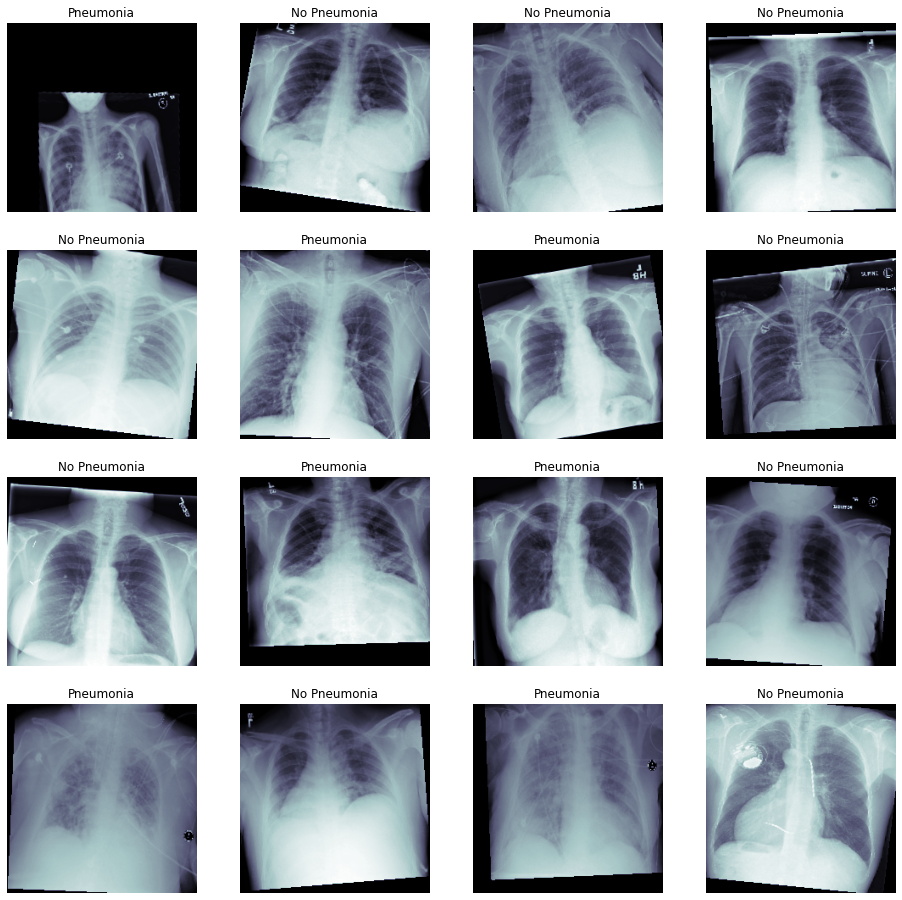

In [8]:
## May want to look at some examples of our augmented training data. 
## This is helpful for understanding the extent to which data is being manipulated prior to training, 
## and can be compared with how the raw data look prior to augmentation

t_x, t_y = next(train_gen)
fig, m_axs = plt.subplots(4, 4, figsize = (16, 16))
for (c_x, c_y, c_ax) in zip(t_x, t_y, m_axs.flatten()):
    c_ax.imshow(c_x[:,:,0], cmap = 'bone')
    if c_y == 1: 
        c_ax.set_title('Pneumonia')
    else:
        c_ax.set_title('No Pneumonia')
    c_ax.axis('off')

## Build your model: 

Recommendation here to use a pre-trained network downloaded from Keras for fine-tuning

In [9]:
def load_pretrained_model(lay_of_interest='block5_pool'):

    model = VGG16(include_top=True, weights='imagenet')
    transfer_layer = model.get_layer(lay_of_interest)
    vgg_model = Model(inputs=model.input, outputs=transfer_layer.output)

    # Freeze all layers except the last convolutional block (block5) for fine-tuning
    for layer in vgg_model.layers[:-4]:
        layer.trainable = False
    for layer in vgg_model.layers:
        print(layer.name, layer.trainable)

    return vgg_model


In [10]:
def build_my_model(learning_rate=1e-4):

    vgg_model = load_pretrained_model()

    my_model = Sequential()
    my_model.add(vgg_model)
    my_model.add(Flatten())
    my_model.add(Dropout(0.5))
    my_model.add(Dense(1024, activation='relu'))
    my_model.add(Dropout(0.5))
    my_model.add(Dense(512, activation='relu'))
    my_model.add(Dropout(0.3))
    my_model.add(Dense(256, activation='relu'))
    my_model.add(Dense(1, activation='sigmoid'))

    try:
        optimizer = Adam(learning_rate=learning_rate)
    except TypeError:          # older Keras versions
        optimizer = Adam(lr=learning_rate)

    my_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['binary_accuracy'])
    return my_model


my_model = build_my_model()
my_model.summary()

## STAND-OUT Suggestion: choose another output layer besides just the last classification layer of your modele
## to output class activation maps to aid in clinical interpretation of your model's results

553467904/553467096 [==============================] - 4s 0us/step
input_1 False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True
Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
model_1 (Model)              (None, 7, 7, 512)         14714688  
_________________________________________________________________
flatten_1 (Flatten)          (None, 25088)             0         
_________________________________________________________________
dropout_1 (Dropout)          (None, 25088)             0         
_________________________________________________________________
dense_1 (Dense)              (None, 

In [11]:
## Below is some helper code that will allow you to add checkpoints to your model,
## This will save the 'best' version of your model by comparing it to previous epochs of training

## We monitor validation loss (lower is better). The 'patience' parameter is set to 10, meaning
## that the model will train for ten epochs without improvement before quitting.

weight_path = "{}_my_model.best.h5".format('xray_class')   # final model WEIGHTS file for submission

checkpoint = ModelCheckpoint(weight_path,
                             monitor='val_loss',
                             verbose=1,
                             save_best_only=True,
                             mode='min',
                             save_weights_only=True)

early = EarlyStopping(monitor='val_loss',
                      mode='min',
                      patience=10)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5, patience=3, verbose=1, min_lr=1e-6)

callbacks_list = [checkpoint, early, reduce_lr]

### Start training! 

In [12]:
## train your model
EPOCHS = 30

# fit_generator exists in older Keras; newer Keras accepts generators in fit()
fit_fn = my_model.fit_generator if hasattr(my_model, 'fit_generator') else my_model.fit

history = fit_fn(train_gen,
                 validation_data=(valX, valY),
                 epochs=EPOCHS,
                 callbacks=callbacks_list)

Epoch 1/30
72/72 [==============================] - 62s 861ms/step - loss: 0.7304 - binary_accuracy: 0.5206 - val_loss: 0.6614 - val_binary_accuracy: 0.6669

Epoch 00001: val_loss improved from inf to 0.66136, saving model to xray_class_my_model.best.h5
Epoch 2/30
72/72 [==============================] - 48s 668ms/step - loss: 0.6764 - binary_accuracy: 0.5884 - val_loss: 0.6223 - val_binary_accuracy: 0.6885

Epoch 00002: val_loss improved from 0.66136 to 0.62231, saving model to xray_class_my_model.best.h5
Epoch 3/30
72/72 [==============================] - 50s 700ms/step - loss: 0.6884 - binary_accuracy: 0.5289 - val_loss: 0.6969 - val_binary_accuracy: 0.6035

Epoch 00003: val_loss did not improve from 0.62231
Epoch 4/30
72/72 [==============================] - 49s 680ms/step - loss: 0.6651 - binary_accuracy: 0.6146 - val_loss: 0.6222 - val_binary_accuracy: 0.7561

Epoch 00004: val_loss improved from 0.62231 to 0.62222, saving model to xray_class_my_model.best.h5
Epoch 5/30
72/72 [===

##### After training for some time, look at the performance of your model by plotting some performance statistics:

Note, these figures will come in handy for your FDA documentation later in the project

In [13]:
## After training, make some predictions to assess your model's overall performance
## Note that detecting pneumonia is hard even for trained expert radiologists,
## so there is no need to make the model perfect.
my_model.load_weights(weight_path)
pred_Y = my_model.predict(valX, batch_size=32, verbose=True).ravel()

1435/1435 [==============================] - 7s 5ms/step


In [14]:
def plot_auc(t_y, p_y):
    fpr, tpr, _ = roc_curve(t_y, p_y)
    roc_auc = auc(fpr, tpr)
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    ax.plot(fpr, tpr, label='Pneumonia (AUC = {:.3f})'.format(roc_auc), linewidth=2)
    ax.plot([0, 1], [0, 1], 'k--', label='Chance')
    ax.set_xlabel('False Positive Rate (1 - Specificity)')
    ax.set_ylabel('True Positive Rate (Sensitivity)')
    ax.set_title('ROC curve')
    ax.legend(loc='lower right')
    plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
    plt.show()
    return roc_auc

## what other performance statistics do you want to include here besides AUC?

def plot_precision_recall_curve(t_y, p_y):
    precision, recall, _ = precision_recall_curve(t_y, p_y)
    ap = average_precision_score(t_y, p_y)
    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    ax.plot(recall, precision, label='Pneumonia (AP = {:.3f})'.format(ap), linewidth=2)
    ax.axhline(t_y.mean(), color='k', linestyle='--', label='Prevalence = {:.2f}'.format(t_y.mean()))
    ax.set_xlabel('Recall (Sensitivity)')
    ax.set_ylabel('Precision (PPV)')
    ax.set_title('Precision-Recall curve')
    ax.legend()
    plt.savefig('pr_curve.png', dpi=150, bbox_inches='tight')
    plt.show()
    return ap


def plot_f1_vs_threshold(t_y, p_y):
    precision, recall, thresholds = precision_recall_curve(t_y, p_y)
    precision, recall = precision[:-1], recall[:-1]    # align with thresholds
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    fig, ax = plt.subplots(1, 1, figsize=(10, 5))
    ax.plot(thresholds, precision, label='Precision')
    ax.plot(thresholds, recall, label='Recall')
    ax.plot(thresholds, f1, label='F1', linewidth=2)
    ax.set_xlabel('Threshold'); ax.set_title('Precision / Recall / F1 vs threshold')
    ax.legend()
    plt.savefig('f1_threshold.png', dpi=150, bbox_inches='tight')
    plt.show()
    return thresholds, precision, recall, f1

#Also consider plotting the history of your model training:

def plot_history(history):
    h = history.history
    acc_key = 'binary_accuracy' if 'binary_accuracy' in h else 'acc'
    n = len(h['loss'])
    fig, axs = plt.subplots(1, 2, figsize=(16, 5))
    axs[0].plot(range(1, n + 1), h['loss'], label='train loss')
    axs[0].plot(range(1, n + 1), h['val_loss'], label='val loss')
    axs[0].set_xlabel('Epoch'); axs[0].set_title('Loss'); axs[0].legend()
    axs[1].plot(range(1, n + 1), h[acc_key], label='train acc')
    axs[1].plot(range(1, n + 1), h['val_' + acc_key], label='val acc')
    axs[1].set_xlabel('Epoch'); axs[1].set_title('Binary accuracy'); axs[1].legend()
    plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
    plt.show()
    return

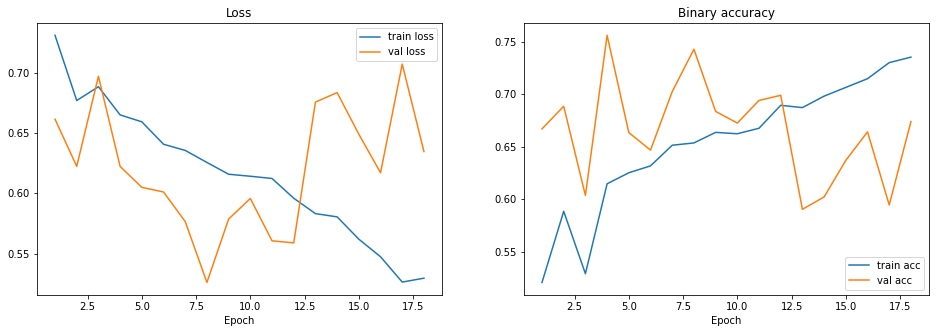

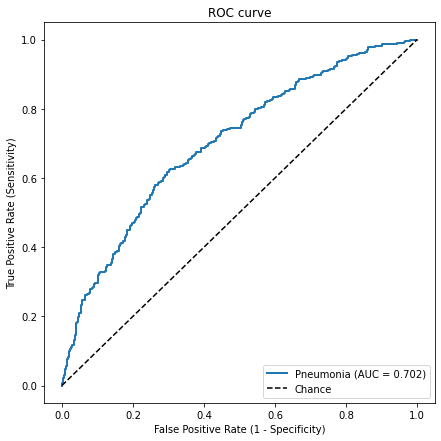

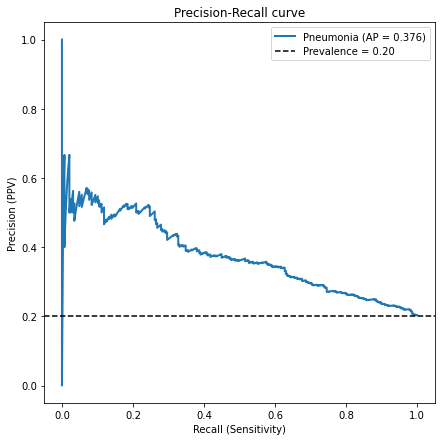

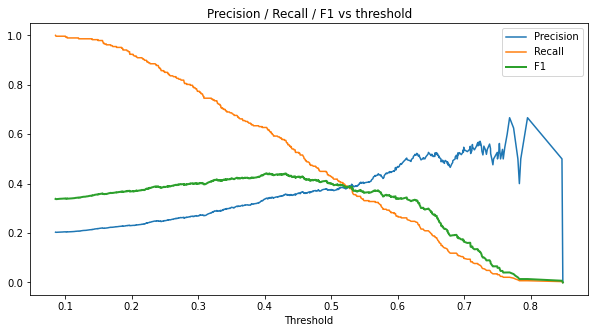

AUC: 0.702 | Average precision: 0.376


In [15]:
## plot figures
plot_history(history)
roc_auc = plot_auc(valY, pred_Y)
ap = plot_precision_recall_curve(valY, pred_Y)
thresholds, precision, recall, f1 = plot_f1_vs_threshold(valY, pred_Y)
print('AUC: {:.3f} | Average precision: {:.3f}'.format(roc_auc, ap))

Once you feel you are done training, you'll need to decide the proper classification threshold that optimizes your model's performance for a given metric (e.g. accuracy, F1, precision, etc.  You decide) 

In [16]:
## Find the threshold that optimize your model's performance,
## and use that threshold to make binary classification. Make sure you take all your metrics into consideration.

# We choose the threshold that maximises F1 on the validation set: it balances catching pneumonia
# (recall / sensitivity) against false alarms (precision), which suits a triage / worklist tool.
best_idx = np.argmax(f1)
YOUR_THRESHOLD = float(thresholds[best_idx])
print('Best threshold (max F1): {:.4f}'.format(YOUR_THRESHOLD))

pred_bin = (pred_Y > YOUR_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(valY, pred_bin).ravel()
print('F1          : {:.3f}'.format(f1_score(valY, pred_bin)))
print('Precision   : {:.3f}'.format(precision_score(valY, pred_bin)))
print('Recall/Sens : {:.3f}'.format(recall_score(valY, pred_bin)))
print('Specificity : {:.3f}'.format(tn / (tn + fp)))
print('NPV         : {:.3f}'.format(tn / (tn + fn) if (tn + fn) else 0))
print('Confusion matrix [[TN FP] [FN TP]]:\n', np.array([[tn, fp], [fn, tp]]))

# for reference: metrics at a few other thresholds
for t in [0.3, 0.4, 0.5, 0.6]:
    pb = (pred_Y > t).astype(int)
    print('thresh {:.1f} -> precision {:.3f}, recall {:.3f}, F1 {:.3f}'.format(
        t, precision_score(valY, pb), recall_score(valY, pb), f1_score(valY, pb)))

# save the parameters the Inference notebook needs
with open('model_config.json', 'w') as f:
    json.dump({'img_mean': IMG_MEAN, 'img_std': IMG_STD, 'threshold': YOUR_THRESHOLD,
               'img_size': list(IMG_SIZE),
               # performance numbers for the FDA submission report
               'auc': float(roc_auc), 'average_precision': float(ap),
               'f1': float(f1_score(valY, pred_bin)),
               'precision': float(precision_score(valY, pred_bin)),
               'recall': float(recall_score(valY, pred_bin)),
               'specificity': float(tn / (tn + fp)),
               'tp': int(tp), 'fp': int(fp), 'tn': int(tn), 'fn': int(fn),
               'epochs_trained': len(history.history['loss']),
               'n_train': int(len(train_data)), 'n_train_pos': int(train_data['pneumonia_class'].sum()),
               'n_val': int(len(val_data)), 'n_val_pos': int(val_data['pneumonia_class'].sum())},
              f, indent=2)
print('saved model_config.json')

Best threshold (max F1): 0.4029
F1          : 0.440
Precision   : 0.340
Recall/Sens : 0.624
Specificity : 0.697
NPV         : 0.881
Confusion matrix [[TN FP] [FN TP]]:
 [[800 348]
 [108 179]]
thresh 0.3 -> precision 0.269, recall 0.774, F1 0.399
thresh 0.4 -> precision 0.337, recall 0.627, F1 0.438
thresh 0.5 -> precision 0.375, recall 0.429, F1 0.400
thresh 0.6 -> precision 0.470, recall 0.268, F1 0.341
saved model_config.json


In [17]:
## Performance by subgroup (device limitations for the FDA report)
## valX/valY are in the same order as val_data (validation generator uses shuffle=False)
val_eval = val_data.iloc[:len(pred_Y)].copy()
val_eval['prob'] = pred_Y
val_eval['pred'] = (pred_Y > YOUR_THRESHOLD).astype(int)
assert (val_eval['pneumonia_class'].values == valY.astype(int)).all()

def subgroup_metrics(d):
    pos, neg = d[d['pneumonia_class'] == 1], d[d['pneumonia_class'] == 0]
    return {'n': int(len(d)), 'n_pos': int(len(pos)),
            'sensitivity': float(pos['pred'].mean()) if len(pos) else None,
            'specificity': float(1 - neg['pred'].mean()) if len(neg) else None}

subgroups = {}
for g in ['M', 'F']:
    subgroups['Gender ' + g] = subgroup_metrics(val_eval[val_eval['Patient Gender'] == g])
for v in ['PA', 'AP']:
    subgroups['View ' + v] = subgroup_metrics(val_eval[val_eval['View Position'] == v])
for lo, hi in [(1, 20), (20, 40), (40, 60), (60, 80), (80, 101)]:
    subgroups['Age {}-{}'.format(lo, hi - 1)] = subgroup_metrics(
        val_eval[(val_eval['Patient Age'] >= lo) & (val_eval['Patient Age'] < hi)])
# comorbidities: does the model still separate pneumonia when these are present?
for dis in ['Infiltration', 'Edema', 'Effusion', 'Atelectasis']:
    subgroups['With ' + dis] = subgroup_metrics(val_eval[val_eval[dis] == 1])
subgroups['No other finding'] = subgroup_metrics(
    val_eval[val_eval['Finding Labels'].isin(['Pneumonia', 'No Finding'])])

sub_df = pd.DataFrame(subgroups).T
display(sub_df)

# add to the config used by the FDA report
with open('model_config.json') as f:
    cfg = json.load(f)
cfg['subgroups'] = subgroups
with open('model_config.json', 'w') as f:
    json.dump(cfg, f, indent=2)

,n,n_pos,sensitivity,specificity
Gender M,860.0,189.0,0.656085,0.676602
Gender F,575.0,98.0,0.561224,0.725367
View PA,846.0,129.0,0.434109,0.822873
View AP,589.0,158.0,0.778481,0.487239
Age 1-19,83.0,19.0,0.684211,0.750000
Age 20-39,402.0,98.0,0.642857,0.710526
Age 40-59,618.0,113.0,0.601770,0.675248
Age 60-79,325.0,56.0,0.607143,0.713755
Age 80-100,7.0,1.0,1.000000,0.500000
With Infiltration,328.0,130.0,0.769231,0.505051


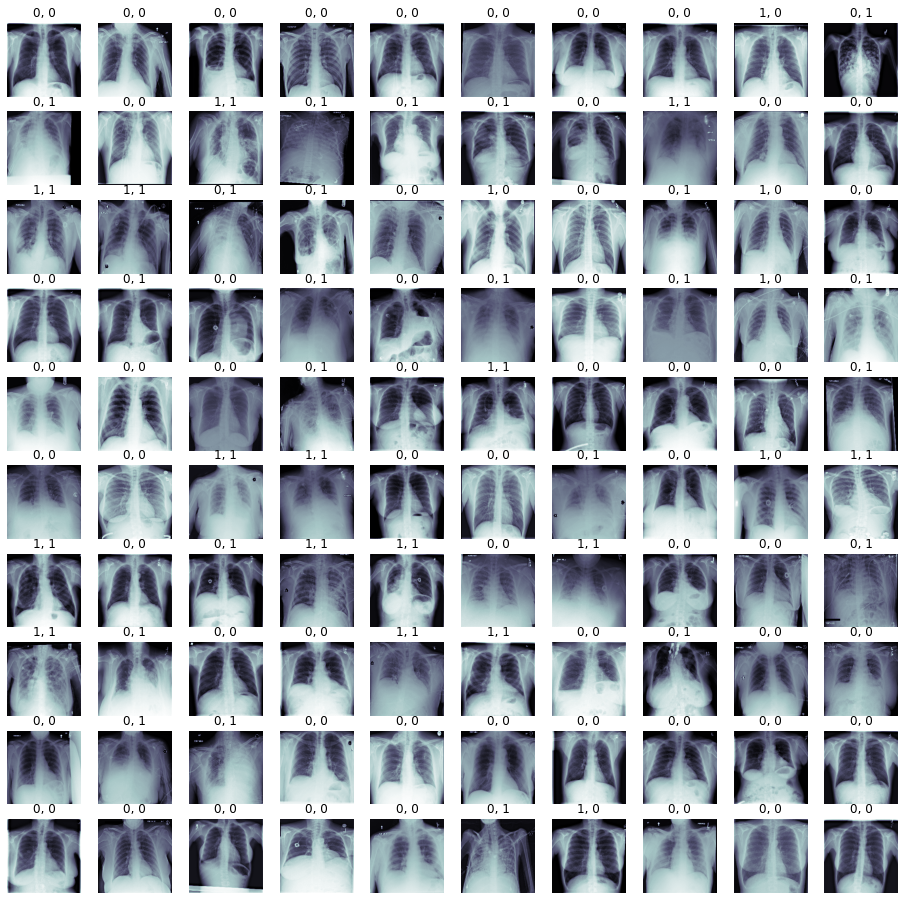

In [18]:
## Let's look at some examples of true vs. predicted with our best model:
## title = 'true label, predicted label'

fig, m_axs = plt.subplots(10, 10, figsize=(16, 16))
i = 0
for (c_x, c_y, c_ax) in zip(valX[0:100], valY[0:100], m_axs.flatten()):
    c_ax.imshow(c_x[:,:,0], cmap='bone')
    if c_y == 1:
        if pred_Y[i] > YOUR_THRESHOLD:
            c_ax.set_title('1, 1')
        else:
            c_ax.set_title('1, 0')
    else:
        if pred_Y[i] > YOUR_THRESHOLD:
            c_ax.set_title('0, 1')
        else:
            c_ax.set_title('0, 0')
    c_ax.axis('off')
    i=i+1

In [19]:
## Just save model architecture to a .json:

model_json = my_model.to_json()
with open("my_model.json", "w") as json_file:
    json_file.write(model_json)

# Submission files produced by this notebook
for f in ['my_model.json', weight_path, 'model_config.json',
          'training_history.png', 'roc_curve.png', 'pr_curve.png', 'f1_threshold.png']:
    print(f, 'exists' if os.path.exists(f) else 'MISSING')

my_model.json exists
xray_class_my_model.best.h5 exists
model_config.json exists
training_history.png exists
roc_curve.png exists
pr_curve.png exists
f1_threshold.png exists
